In [1]:
import sys
sys.path.append('../')
from qacits import calibrate_qacits, run_qacits
import os
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import yappi
%matplotlib inline

### 1/ Load demo data

In [2]:
os.chdir(os.path.normpath(os.path.expandvars('$HOME/QACITS')))
psf_OFF = fits.getdata('data/offaxis_PSF_L_CVC.fits')
psf_ON_calib = fits.getdata('data/onaxis_PSF_L_CVC_calib.fits.gz')
psf_ON_jitter = fits.getdata('data/onaxis_PSF_L_CVC_jitter.fits.gz')
tt_lamD_calib = fits.getdata('data/point_8s_100ms_L_calib.fits')
tt_lamD_jitter = fits.getdata('data/point_8s_100ms_L_jitter.fits')
img_sampling = 3.98 # pix per lambda/D
lamD = 21.78 # mas per lambda/D
dit = 0.1 # seconds

### 2/ QACITS default parameters

In [3]:
qacits_params = dict(
    force = None,
    coeffs = {'inner':1, 'outer':1, 'full':1},
    radii = {'inner':(0,1.7), 'outer':(1.7,2.3), 'full':(0, 2.7)},
    nbin = 0,
    ratio = 0,
    phase_tolerance = 60,
    modul_tolerance = 0.33,
    small_tt_regime = 0.3,
    large_tt_regime = 0.2, 
)

### 3/ Calibrate QACITS with known tip-tilt

psf_flux = 0.26036 (photutils is True)

Model calibration results:
Inner slope = 0.218
Outer slope = 0.121
Full coeff  = 1.373


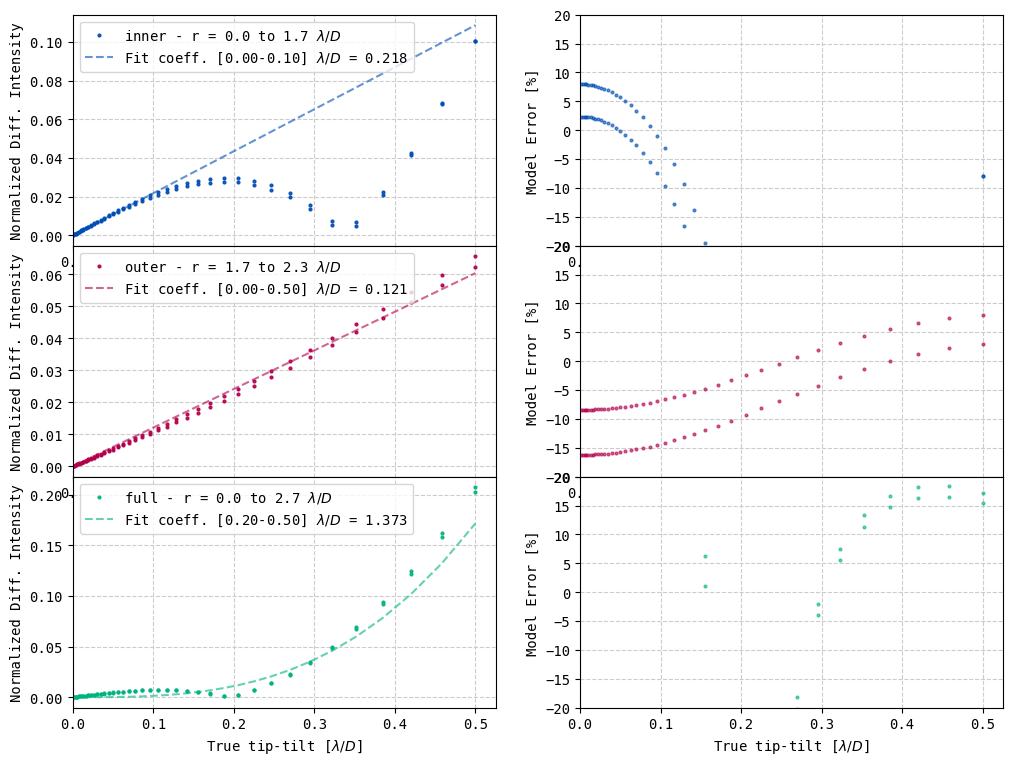

In [4]:
qacits_params['coeffs'] = calibrate_qacits(psf_ON_calib, psf_OFF, img_sampling, tt_lamD_calib, plot_fig=True, verbose=True)
qacits_params['force'] = 'outer'
plt.show()

### 4/ Run QACITS: pointing error estimation


    name - It has information on the function name which was executed.
    ncall - It holds an integer representing the number of times the function was called. This sometimes returns two numbers separated by a slash. In that case on number represents an actual number of time function called excluding recursive calls and another represents the total time function called including recursive calls.
    tsub - It represents time spent in function calls excluding sub-function calls.
    ttot - It represents the total time taken to execute a function.
    tavg - It represents the average time spent per call of that function.



Clock type: CPU
Ordered by: totaltime, desc

name                                  ncall  tsub      ttot      tavg      
..nel_49098/1703953499.py:1 <module>  4/3    0.000000  8.104000  2.026000
..:3541 ZMQInteractiveShell.run_code  3      0.000000  8.104000  2.701333
../qacits/run_qacits.py:6 run_qacits  100    0.048000  8.104000  0.081040
..ts/util/psf_flux.py:111 get_all_di  100    0.000000  7.772000  0.077720
..cits/util/psf_flux.py:46 get_di_xy  600    0.524000  7.772000  0.012953
..otometry.py:21 aperture_photometry  2900   0.176000  7.304000  0.002519
..e/table.py:2126 QTable.__setitem__  11600  0.052000  5.592000  0.000482
..le/table.py:2332 QTable.add_column  11600  0.288000  5.488000  0.000473
..y:1261 QTable._convert_data_to_col  11600  0.176000  2.044000  0.000176
..stropy/table/column.py:68 col_copy  14500  0.068000  1.448000  0.000100
..n.py:707 Column.__array_finalize__  17400  0.136000  1.400000  0.000080
../column.py:1271 Column.__setattr__  223..  0.648000  1.360000 

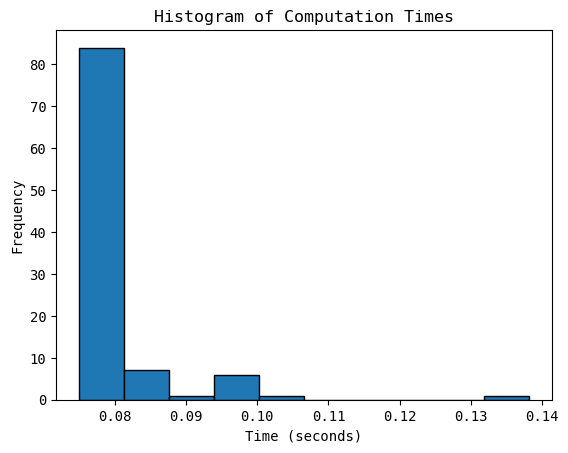

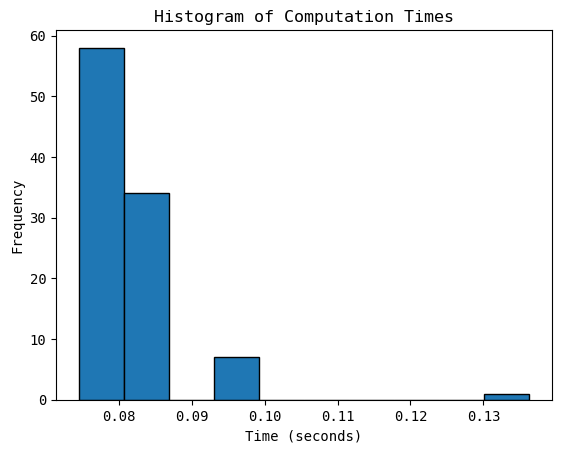

In [16]:
import time

yappi.clear_stats()
yappi.set_clock_type('cpu') # 'wall'
yappi.start()

nrepeat= 100
# t1 = time.perf_counter(), time.process_time()

elapsed_time =[]
for i in range(nrepeat):
    start_time = time.time()
    tiptilt_estimate = run_qacits(psf_ON_jitter[0], psf_OFF, img_sampling, **qacits_params)
    end_time = time.time()
    elapsed_time.append(end_time - start_time)

# t2 = time.perf_counter(), time.process_time()

# print(f" Real time: {t2[0] - t1[0]:.2f} seconds")
# print(f" CPU time: {t2[1] - t1[1]:.2f} seconds")

yappi.stop()
yappi.get_func_stats().print_all()
# yappi.get_func_stats().print_all()
yappi.get_thread_stats().print_all()


plt.figure()
plt.hist(elapsed_time, bins=10, edgecolor='black')
plt.title('Histogram of Computation Times')
plt.xlabel('Time (seconds)')
plt.ylabel('Frequency')
plt.show()

# Extract the computation times
# stats = yappi.get_func_stats()
# times = []
# for stat in stats:
#     if stat.name == 'run_qacits':
#         times.append(stat.ttot)

# # Plot the histogram
# plt.hist(times, bins=10, edgecolor='black')
# plt.title('Histogram of Computation Times')
# plt.xlabel('Time (seconds)')
# plt.ylabel('Frequency')
# plt.show()
# for stat in stats:
#     print(f"Function: {stat.name}")
#     print(f"  Total Time: {stat.ttot * 1e6:.3f} μs")
#     print(f"  Average Time: {stat.tavg * 1e6:.3f} μs")
#     print(f"  Call Count: {stat.ncall}")
#     print()

In [ ]:
stats.ca

1

In [5]:
tiptilt_estimate = run_qacits(psf_ON_jitter, psf_OFF, img_sampling, **qacits_params)

In [ ]:
# fits.writeto('test_exact_false.fits', tiptilt_estimate)
# fits.writeto('test_exact_true.fits', tiptilt_estimate)

In [5]:
tiptilt_estimate_true = fits.getdata('test_exact_true.fits')
tiptilt_estimate_false = fits.getdata('test_exact_false.fits')


### 5/ Figure: residuals

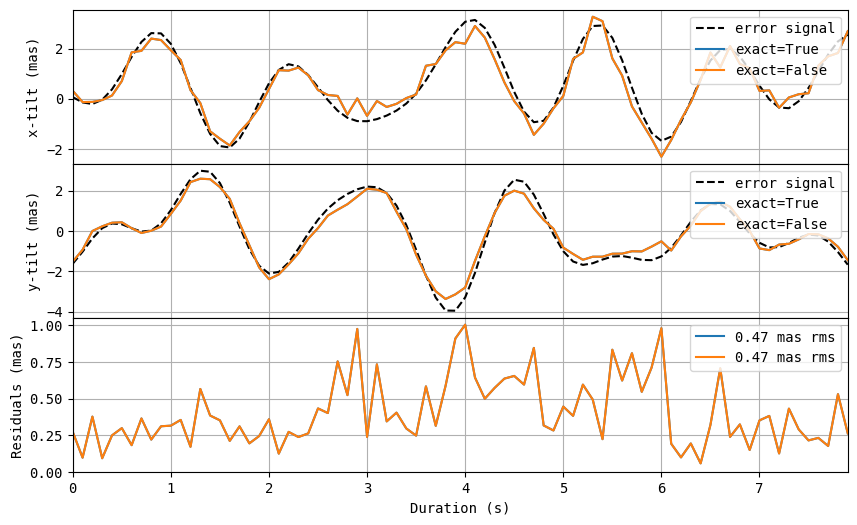

In [ ]:
# convert to mas
tt_est = -tiptilt_estimate_true[:,0:2]*lamD
tt_est_f = -tiptilt_estimate_false[:, 0:2]*lamD #-tiptilt_estimate_false[:,0:2]*lamD
tt_true = tt_lamD_jitter*lamD
# rms error
dist = np.sqrt((tt_est[:,0]-tt_true[:,0])**2 + (tt_est[:,1]-tt_true[:,1])**2)
dist_f = np.sqrt((tt_est_f[:,0]-tt_true[:,0])**2 + (tt_est_f[:,1]-tt_true[:,1])**2)

rms = np.sqrt(np.mean(dist**2))
rms_f = np.sqrt(np.mean(dist_f**2))

# figure
ts = dit*np.arange(len(tt_lamD_jitter))

fig, (a0, a1, a2) = plt.subplots(3, 1, figsize=(10,6), sharex=True)
fig.subplots_adjust(hspace=0)

a0.plot(ts, tt_true[:,0], label='error signal', color='k', linestyle='--')
a0.plot(ts, tt_est[:,0], label='exact=True')
a0.plot(ts, tt_est_f[:,0], label='exact=False')
a0.set_ylabel('x-tilt (mas)')
a0.legend(loc='upper right'); a0.grid(True)
a0.set_xlim((0, ts[-1]))

a1.plot(ts, tt_true[:,1], label='error signal', color='k', linestyle='--')
a1.plot(ts, tt_est[:,1], label='exact=True')
a1.plot(ts, tt_est_f[:,1], label='exact=False')
a1.set_ylabel('y-tilt (mas)')
a1.legend(loc='upper right'); a1.grid(True)
a1.set_xlim((0, ts[-1]))

a2.plot(ts, dist, label='%.2f mas rms'%rms)
a2.plot(ts, dist_f, label='%.2f mas rms'%rms_f)

a2.set_xlabel('Duration (s)')
a2.set_ylabel('Residuals (mas)')
a2.legend(loc='upper right'); a2.grid(True)
a2.set_xlim((0, ts[-1]))
a2.set_ylim(bottom=0)
plt.show()